# Stage 1 & 2: Data Loading and Face Recognition Model

Covers:
- Loading the LFW dataset (112×112 pre-aligned face images)
- Building and loading ElasticFace-Arc (iResNet-100)
- Extracting cosine similarity scores for all 900 pairs
- Sanity-check histogram: genuine scores should be clearly higher than imposter scores

In [1]:
!pip install timm -q

## ⚙️ CONFIG — edit only this cell
Set dataset paths and all experiment parameters here before running anything else.

In [2]:
import torch

# -----------------------------------------------------------------
# Paths — update to your Kaggle dataset slug
# After adding the dataset to the notebook, check /kaggle/input/ for the slug
IMAGES_DIR   = "/kaggle/input/datasets/xitij27/hcml-lfw-dataset/imgs"
WEIGHTS_PATH = "/kaggle/input/models/xitij27/elastic-face-arc/pytorch/default/1/ElasticFaceArc.pth"
OUTPUT_DIR   = "/kaggle/working/"

# -----------------------------------------------------------------
# Dataset structure (from approach.md)
# Pairs  0-299  : genuine  (images    0-599)
# Pairs 300-599 : imposter (images  600-1199)
# Pairs 600-899 : genuine  (images 1200-1799)
N_PAIRS        = 900
N_GENUINE_1    = 300
N_IMPOSTER     = 300
N_GENUINE_2    = 300

# -----------------------------------------------------------------
# Model
NUM_FEATURES   = 512           # embedding dimensionality
IMG_SIZE       = 112           # images are pre-cropped to 112x112

# -----------------------------------------------------------------
# Decision threshold for genuine/imposter classification
THRESHOLD      = 0.30

# -----------------------------------------------------------------
# Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB


## Imports

In [3]:
import os
import numpy as np
import cv2
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

## ElasticFace-Arc Backbone (iResNet-100)
Inlined from `elastic_resnet.py` so the notebook is self-contained.

In [4]:
def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=dilation, groups=groups, bias=False, dilation=dilation)

def conv1x1(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


class IBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None,
                 groups=1, base_width=64, dilation=1, use_se=False):
        super().__init__()
        self.bn1        = nn.BatchNorm2d(inplanes, eps=1e-05)
        self.conv1      = conv3x3(inplanes, planes)
        self.bn2        = nn.BatchNorm2d(planes, eps=1e-05)
        self.prelu      = nn.PReLU(planes)
        self.conv2      = conv3x3(planes, planes, stride)
        self.bn3        = nn.BatchNorm2d(planes, eps=1e-05)
        self.downsample = downsample
        self.stride     = stride

    def forward(self, x):
        identity = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        return out


class IResNet(nn.Module):
    fc_scale = 7 * 7
    def __init__(self, block, layers, dropout=0, num_features=512,
                 groups=1, width_per_group=64,
                 replace_stride_with_dilation=None):
        super().__init__()
        self.inplanes   = 64
        self.dilation   = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        self.groups     = groups
        self.base_width = width_per_group
        self.conv1      = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1        = nn.BatchNorm2d(64, eps=1e-05)
        self.prelu      = nn.PReLU(64)
        self.layer1     = self._make_layer(block, 64,  layers[0], stride=2)
        self.layer2     = self._make_layer(block, 128, layers[1], stride=2,
                                           dilate=replace_stride_with_dilation[0])
        self.layer3     = self._make_layer(block, 256, layers[2], stride=2,
                                           dilate=replace_stride_with_dilation[1])
        self.layer4     = self._make_layer(block, 512, layers[3], stride=2,
                                           dilate=replace_stride_with_dilation[2])
        self.bn2        = nn.BatchNorm2d(512 * block.expansion, eps=1e-05)
        self.dropout    = nn.Dropout(p=dropout, inplace=True)
        self.fc         = nn.Linear(512 * block.expansion * self.fc_scale, num_features)
        self.features   = nn.BatchNorm1d(num_features, eps=1e-05)
        nn.init.constant_(self.features.weight, 1.0)
        self.features.weight.requires_grad = False
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, 0, 0.1)
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride=1, dilate=False):
        downsample    = None
        prev_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                nn.BatchNorm2d(planes * block.expansion, eps=1e-05),
            )
        layers = [block(self.inplanes, planes, stride, downsample,
                        self.groups, self.base_width, prev_dilation)]
        self.inplanes = planes * block.expansion
        for _ in range(1, num_blocks):
            layers.append(block(self.inplanes, planes, groups=self.groups,
                                base_width=self.base_width, dilation=self.dilation))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        x = self.features(x)
        return x


def elastic_iresnet100(**kwargs):
    return IResNet(IBasicBlock, [3, 13, 30, 3], **kwargs)

## Data Loading Utilities

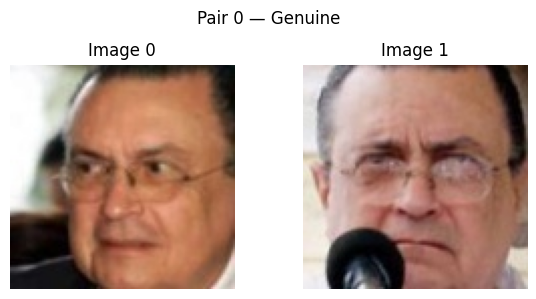

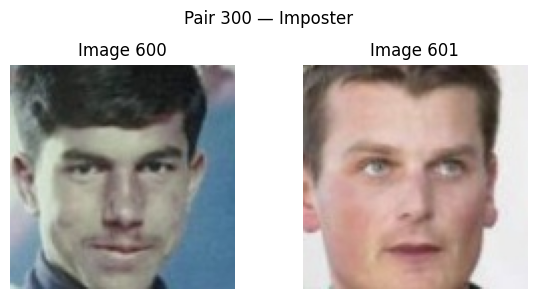

In [5]:
def preprocess(img):
    """uint8 RGB (H,W,3) numpy -> float32 tensor (3,H,W) in [-1, 1]."""
    img = ((img / 255.0) - 0.5) / 0.5
    return torch.tensor(np.transpose(img, (2, 0, 1)).astype('float32'))


def load_image_raw(pair_idx, which):
    """Load raw RGB numpy array. which=0 -> image A, which=1 -> image B."""
    path = os.path.join(IMAGES_DIR, f"{pair_idx * 2 + which}.jpg")
    img  = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Missing: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def load_pair(pair_idx):
    """Return (img_a, img_b) as preprocessed tensors on DEVICE."""
    img_a = preprocess(load_image_raw(pair_idx, 0)).to(DEVICE)
    img_b = preprocess(load_image_raw(pair_idx, 1)).to(DEVICE)
    return img_a, img_b


def is_genuine(pair_idx):
    return pair_idx < N_GENUINE_1 or pair_idx >= N_GENUINE_1 + N_IMPOSTER


def tensor_to_uint8(t):
    """(3,H,W) float tensor in [-1,1] -> (H,W,3) uint8 numpy."""
    img = t.detach().cpu().numpy().transpose(1, 2, 0)
    img = np.clip((img * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)
    return img


def show_pair(pair_idx):
    label = 'Genuine' if is_genuine(pair_idx) else 'Imposter'
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(load_image_raw(pair_idx, 0)); axes[0].set_title(f"Image {pair_idx*2}")
    axes[1].imshow(load_image_raw(pair_idx, 1)); axes[1].set_title(f"Image {pair_idx*2+1}")
    for ax in axes: ax.axis('off')
    fig.suptitle(f"Pair {pair_idx} — {label}")
    plt.tight_layout(); plt.show()


# Sanity check
show_pair(0)
show_pair(300)

## Load Model

In [6]:
def load_model():
    m = elastic_iresnet100(num_features=NUM_FEATURES)
    state = torch.load(WEIGHTS_PATH, map_location=DEVICE)
    if 'state_dict' in state:
        state = state['state_dict']
    m.load_state_dict(state)
    m.to(DEVICE).eval()
    return m


@torch.no_grad()
def get_embedding(img_tensor):
    if img_tensor.dim() == 3:
        img_tensor = img_tensor.unsqueeze(0)
    return model(img_tensor)


model = load_model()
print(f"Parameters : {sum(p.numel() for p in model.parameters()):,}")

# Quick test
for idx, label in [(0, 'genuine'), (300, 'imposter')]:
    a, b = load_pair(idx)
    sim = F.cosine_similarity(get_embedding(a), get_embedding(b), dim=1).item()
    tag = 'MATCH' if sim > THRESHOLD else 'NO MATCH'
    print(f"Pair {idx:3d} ({label:8s}): sim = {sim:.4f}  [{tag}]")

Parameters : 65,156,160
Pair   0 (genuine ): sim = 0.7292  [MATCH]
Pair 300 (imposter): sim = -0.0046  [NO MATCH]


## Extract Embeddings for All 900 Pairs

In [7]:
genuine_sims  = []
imposter_sims = []

for i in tqdm(range(N_PAIRS), desc="Extracting embeddings"):
    a, b = load_pair(i)
    sim  = F.cosine_similarity(get_embedding(a), get_embedding(b), dim=1).item()
    (genuine_sims if is_genuine(i) else imposter_sims).append(sim)

genuine_sims  = np.array(genuine_sims)
imposter_sims = np.array(imposter_sims)

print(f"Genuine  — n={len(genuine_sims):3d}  mean={genuine_sims.mean():.4f}  std={genuine_sims.std():.4f}")
print(f"Imposter — n={len(imposter_sims):3d}  mean={imposter_sims.mean():.4f}  std={imposter_sims.std():.4f}")

Extracting embeddings:   0%|          | 0/900 [00:00<?, ?it/s]

Genuine  — n=600  mean=0.7231  std=0.0981
Imposter — n=300  mean=0.0020  std=0.0692


## Sanity Check: Score Distribution
The two distributions should be clearly separated. If they overlap heavily, the model weights or preprocessing is wrong.

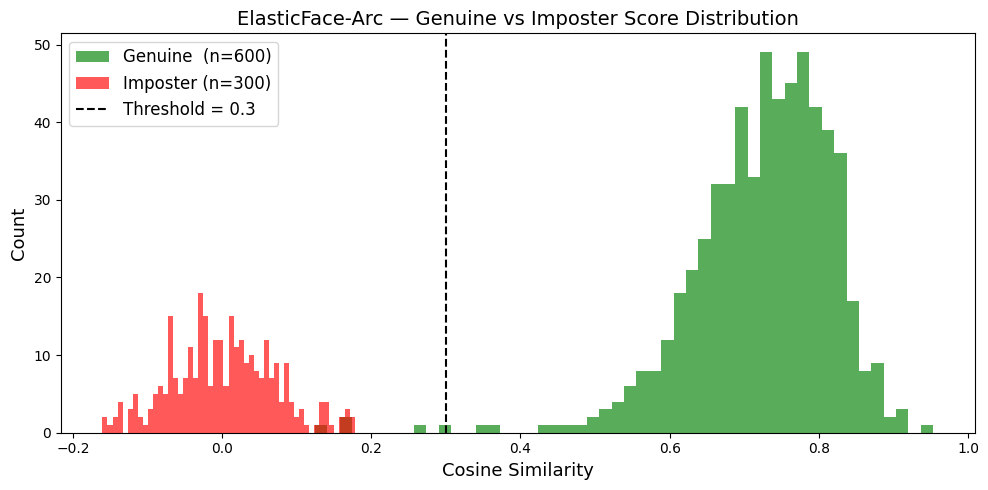

Accuracy @ threshold 0.3 : 0.9956
TAR (True Accept Rate)           : 0.9933
TNR (True Reject Rate)           : 1.0000


In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(genuine_sims,  bins=50, alpha=0.65, color='green',
        label=f'Genuine  (n={len(genuine_sims)})')
ax.hist(imposter_sims, bins=50, alpha=0.65, color='red',
        label=f'Imposter (n={len(imposter_sims)})')
ax.axvline(THRESHOLD, color='black', linestyle='--', lw=1.5,
           label=f'Threshold = {THRESHOLD}')
ax.set_xlabel('Cosine Similarity', fontsize=13)
ax.set_ylabel('Count', fontsize=13)
ax.set_title('ElasticFace-Arc — Genuine vs Imposter Score Distribution', fontsize=14)
ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'similarity_histogram.png'), dpi=150)
plt.show()

tp  = (genuine_sims  > THRESHOLD).sum()
tn  = (imposter_sims <= THRESHOLD).sum()
acc = (tp + tn) / N_PAIRS
print(f"Accuracy @ threshold {THRESHOLD} : {acc:.4f}")
print(f"TAR (True Accept Rate)           : {tp / len(genuine_sims):.4f}")
print(f"TNR (True Reject Rate)           : {tn / len(imposter_sims):.4f}")